In [6]:
#partie 1 :Introduction au Dataset
# importer et charger le dataset
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

df = pd.read_csv("https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")

In [7]:
# visualiser les premières lignes
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [22]:
#identifier les types de données
df.dtypes
#Séparer numériques et catégorielles
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

print("Variables numériques    :", num_cols)
print("Variables catégorielles :", cat_cols)

Variables numériques    : ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']
Variables catégorielles : ['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [8]:
#SÉPARATION DES DONNÉES
X = df.drop(columns=["Survived"])
y = df["Survived"]
# Découpage train/test : 80 % / 20 %
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.20, stratify=y, random_state=42)
print("X_train :", X_train.shape, "| X_test :", X_test.shape)
print("y_train :", y_train.shape, "| y_test :", y_test.shape)


X_train : (712, 11) | X_test : (179, 11)
y_train : (712,) | y_test : (179,)


In [23]:
# verifier les valeurs manquantes
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [24]:
#PARTIE 2 :Nettoyage des Données
#Identifier les colonnes avec des valeurs manquantes
df_clean = df.copy()
df_clean.isnull().sum()
missing_pct = (df_clean.isnull().mean() * 100).round(2)
missing_pct[missing_pct > 0].sort_values(ascending=False)


deck           77.22
age            19.87
embarked        0.22
embark_town     0.22
dtype: float64

In [25]:
#Variables numériques : remplacer par la médiane
df_clean["age"] = df_clean["age"].fillna(df_clean["age"].median())
df_clean["age"].isnull().sum() # verification

np.int64(0)

In [26]:
# Variables catégorielles : remplacer par le mode
df_clean["embarked"] = df_clean["embarked"].fillna(df_clean["embarked"].mode()[0])
df_clean["embark_town"] = df_clean["embark_town"].fillna(df_clean["embark_town"].mode()[0])
print(df_clean[["embarked", "embark_town"]].isnull().sum()) # verification


embarked       0
embark_town    0
dtype: int64


In [27]:
#Supprimer les variables avec plus de 40 % de valeurs manquantes
pct = df_clean.isnull().mean() * 100
cols_a_supprimer = pct[pct > 40].index.tolist()
print(cols_a_supprimer)
df_clean = df_clean.drop(columns=cols_a_supprimer)

['deck']


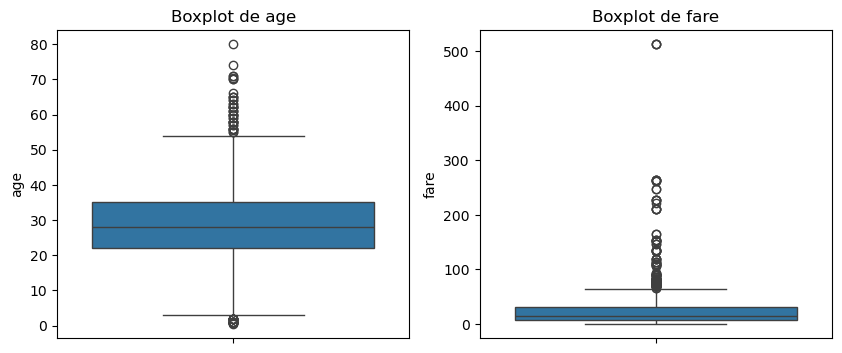

In [28]:
#Détecter avec des boxplots 
import matplotlib.pyplot as plt
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["age", "fare"]):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(f"Boxplot de {col}")
plt.show()

In [29]:

# Remplacer ou supprimer les valeurs aberrantes
# Définir les bornes (règle de l’IQR)
def bornes(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr
# Option A, remplacer par la médiane
df_med = df_clean.copy()
for col in ["age", "fare"]:
    bas, haut = bornes(df_med[col])
    masque = (df_med[col] < bas) | (df_med[col] > haut)
    print(col, ":", masque.sum(), "valeurs remplacées")
    df_med.loc[masque, col] = df_med[col].median()
print(df_med.shape)

age : 66 valeurs remplacées
fare : 116 valeurs remplacées
(891, 14)


In [30]:
# Supprimer les lignes contenant des valeurs aberrantes
df_sup = df_clean.copy()
for col in ["age", "fare"]:
    bas, haut = bornes(df_sup[col])
    df_sup = df_sup[(df_sup[col] >= bas) & (df_sup[col] <= haut)]
print(df_sup.shape)
print("Lignes supprimées :", len(df_clean) - len(df_sup))

(718, 14)
Lignes supprimées : 173


In [31]:
# Partie 3 : Transformation des Données
#Identifier les colonnes catégorielles
cat_cols = df_med.select_dtypes(exclude="number").columns.tolist()
print(cat_cols)

['sex', 'embarked', 'class', 'who', 'adult_male', 'embark_town', 'alive', 'alone']


In [32]:
# Encodage one-hot des variables nominales
df_enc = df_med.copy()
df_enc = pd.get_dummies(df_enc, columns=["sex", "embarked"], drop_first=True, dtype=int)
df_enc.head()

,survived,pclass,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone,sex_male,embarked_Q,embarked_S
0,0,3,22.0,1,0,7.2500,Third,man,True,Southampton,no,False,1,0,1
1,1,1,38.0,1,0,14.4542,First,woman,False,Cherbourg,yes,False,0,0,0
2,1,3,26.0,0,0,7.9250,Third,woman,False,Southampton,yes,True,0,0,1
3,1,1,35.0,1,0,53.1000,First,woman,False,Southampton,yes,False,0,0,1
4,0,3,35.0,0,0,8.0500,Third,man,True,Southampton,no,True,1,0,1


In [42]:
# Encodage numérique de la variable ordinale
df_enc["class"] = df_enc["class"].astype(str).map({"First": 1, "Second": 2, "Third": 3})
print(df_enc["class"].value_counts())


Series([], Name: count, dtype: int64)


In [50]:
# Normalisation (Min-Max) dans [0, 1]

from sklearn.preprocessing import MinMaxScaler
cols_to_scale = ["age", "fare", "sibsp", "parch"]
df_minmax = df_enc.copy()
df_minmax[cols_to_scale] = MinMaxScaler().fit_transform(df_enc[cols_to_scale])

print(df_minmax[cols_to_scale].agg(["min", "max"]))

     age  fare  sibsp  parch
min  0.0   0.0    0.0    0.0
max  1.0   1.0    1.0    1.0


In [51]:
#Standardisation (Z-score)
from sklearn.preprocessing import StandardScaler
df_std = df_enc.copy()
df_std[cols_to_scale] = StandardScaler().fit_transform(df_enc[cols_to_scale])
print(df_std[cols_to_scale].agg(["mean", "std"]).round(3))

        age   fare  sibsp  parch
mean -0.000 -0.000  0.000  0.000
std   1.001  1.001  1.001  1.001


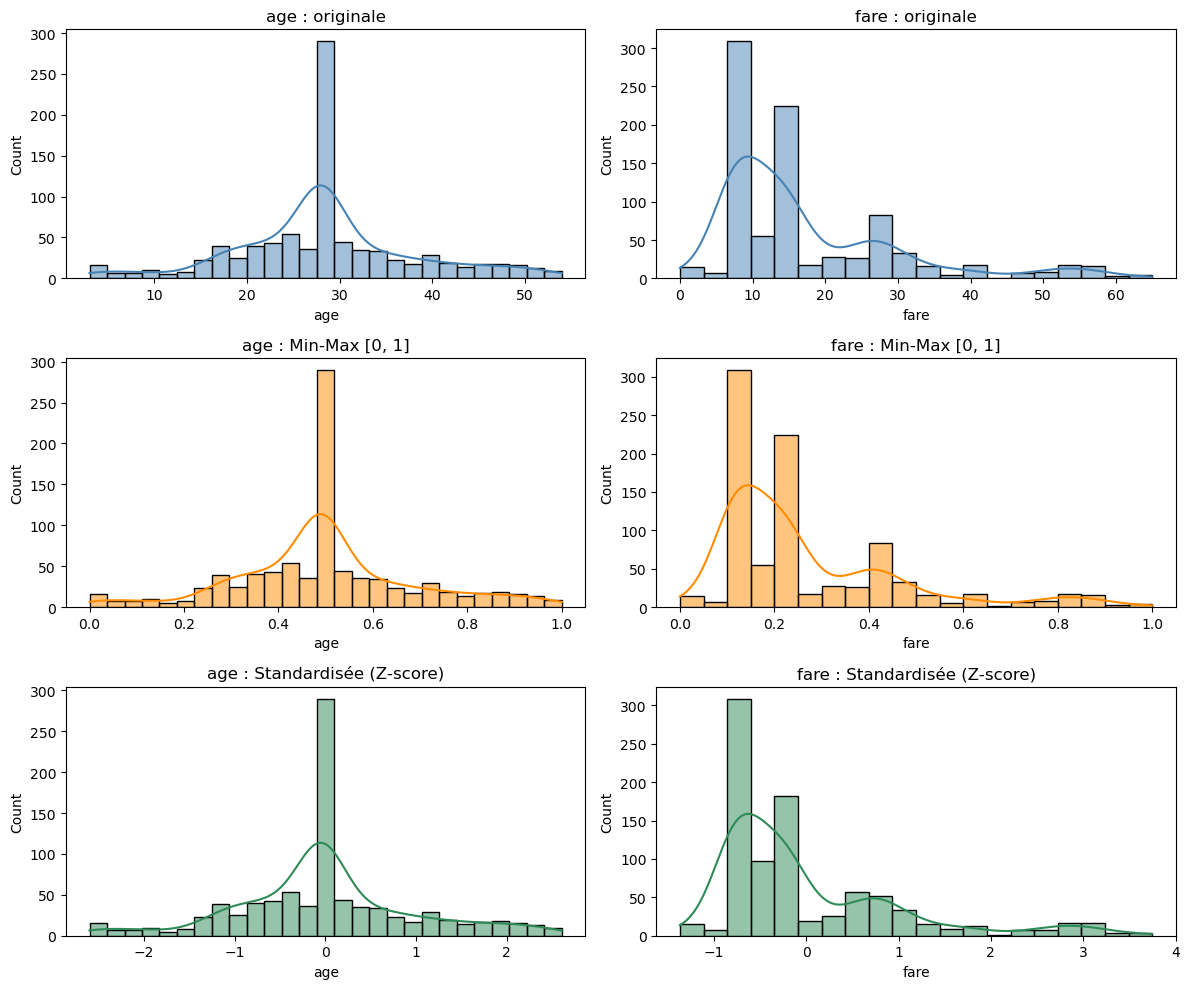

In [52]:
# Comparer les distributions avec des histogrammes
import matplotlib.pyplot as plt
import seaborn as sns
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for j, col in enumerate(["age", "fare"]):
    sns.histplot(df_enc[col], kde=True, ax=axes[0, j], color="steelblue")
    axes[0, j].set_title(f"{col} : originale")
    sns.histplot(df_minmax[col], kde=True, ax=axes[1, j], color="darkorange")
    axes[1, j].set_title(f"{col} : Min-Max [0, 1]")
    sns.histplot(df_std[col], kde=True, ax=axes[2, j], color="seagreen")
    axes[2, j].set_title(f"{col} : Standardisée (Z-score)")
plt.tight_layout()
plt.show()

In [53]:
# Identifier le déséquilibre des classes
print(df_std["survived"].value_counts())

survived
0    549
1    342
Name: count, dtype: int64


In [54]:
# Gestion du déséquilibre 
# Préparation
X = df_std.drop(columns="survived")
y = df_std["survived"]
print(y.value_counts())
# Sous-échantillonnage (undersampling)
from sklearn.utils import resample

df_maj = df_std[df_std["survived"] == 0]   # classe majoritaire
df_min = df_std[df_std["survived"] == 1]   # classe minoritaire

df_maj_reduit = resample(df_maj, replace=False, n_samples=len(df_min), random_state=42)
df_under = pd.concat([df_maj_reduit, df_min]).sample(frac=1, random_state=42)

print(df_under["survived"].value_counts())

survived
0    549
1    342
Name: count, dtype: int64
survived
1    342
0    342
Name: count, dtype: int64


In [56]:
# Sur-échantillonnage avec SMOTE
!pip install imbalanced-learn

In [58]:
print(X.dtypes)
print("Valeurs manquantes :", X.isnull().sum().sum())

pclass           int64
age            float64
sibsp          float64
parch          float64
fare           float64
class          float64
who             object
adult_male        bool
embark_town     object
alive           object
alone             bool
sex_male         int64
embarked_Q       int64
embarked_S       int64
dtype: object
Valeurs manquantes : 891


In [59]:
df_std = df_std.drop(columns=["class", "who", "embark_town", "adult_male", "alone", "alive"], errors="ignore")
X = df_std.drop(columns="survived")
y = df_std["survived"]
print(X.dtypes)

pclass          int64
age           float64
sibsp         float64
parch         float64
fare          float64
sex_male        int64
embarked_Q      int64
embarked_S      int64
dtype: object
